# Enantiomer pairs: which mirror image is the more active one

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/11_enantiomer_pairs.ipynb)

Two **enantiomers** are molecules that are mirror images of each other. They have the same bonds
and the same distances between atoms. A protein is made of one hand only, so it can bind one of
the two better than the other. The more active one is called the **eutomer**, the less active
one the **distomer**. This notebook asks one question: can the program say which of the two is
the eutomer?

The rotation-invariant kernel of the second notebook cannot. It counts pairs of atoms at a
distance, and a mirror image has every distance in the same amounts. This makes the question
easy to audit, because the answer of a model that cannot see handedness is known in advance. The
notebook does four things.

1. It looks at a series of 3,834 enantiomer pairs from ChEMBL, and at one pair in detail.
2. It uses the exact null: a model that cannot see handedness must name the better enantiomer in
   exactly 50.0 % of the pairs. A score that is not exactly 50.0 % shows a fault in the folds.
3. It adds the handedness channels of `cmfqsar/stereo.py` and reads where they work.
4. It compares them with a rule that needs no field: one bit for each target, the configuration
   code (R or S) that was the better one more often.

Running time: about two minutes.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## The series: 3,834 pairs of mirror images

The files are `examples/enantiomers/*.sdf`, one for each of 54 targets. `examples/make_enantiomer_examples.py`
builds them from the ChEMBL web service (CC BY-SA 3.0; the identifiers of the molecule, the assay
and the document are kept in every record). The download takes about two hours, so the notebook
only reads the files. A pair is usable under five rules.

- The two molecules are mirror images: inverting every tetrahedral centre of one gives the other.
  This is tested on the structures, never on a name or a CIP letter, so diastereomers are refused.
- The configuration is given in the record and is confirmed on the built three-dimensional structure.
- Both potencies come from one assay and one type of measurement.
- The second structure is the reflection of the first, not a second embedding.
- Pairs are never selected by how much their potencies differ.

The script that reads the files, `benchmarks/run_enantiomers.py`, measured this series for the
manual. The notebook uses its functions, so that every number can be compared with
`benchmarks/results/enantiomers/table.md`. The kernel cache of the benchmarks is switched off.

54 targets, 3834 pairs, 7668 molecules
difference between the two potencies of a pair (pAffinity, log units):
  exactly equal            130 pairs    3.4 %
  up to 0.3 log units     1152 pairs   30.0 %
  0.3 to 0.5               552 pairs   14.4 %
  0.5 to 1.0               877 pairs   22.9 %
  1.0 to 2.0               852 pairs   22.2 %
  above 2.0                271 pairs    7.1 %
median 0.55, largest 4.61
stereocentres in a pair: one 2461 (64 %), two 1137, three or more 236


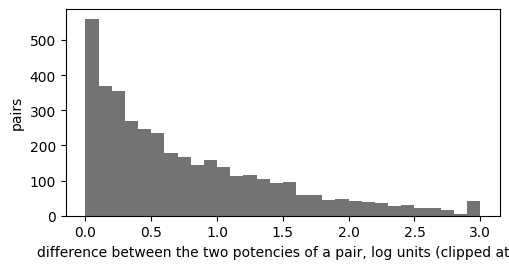

In [2]:
import contextlib
import glob
import io
import json
import os
import sys

os.environ["CMF_KERNEL_CACHE"] = "0"
sys.path.insert(0, "benchmarks")

import matplotlib.pyplot as plt
import numpy as np
from rdkit import Chem, RDLogger

RDLogger.DisableLog("rdApp.*")
import run_enantiomers as en            # the loaders, folds, fits and scores of this series

paths = sorted(glob.glob(os.path.join(en.DATA, "*.sdf")))
sets, whole = en.gather(paths)
pairs_all = en.pair_index(whole)
potency = whole["y"]
gap = np.array([abs(potency[i] - potency[j]) for i, j in pairs_all])
print("%d targets, %d pairs, %d molecules" % (len(sets), len(pairs_all), len(potency)))

ranges = [("exactly equal", gap <= 1e-9), ("up to 0.3 log units", (gap > 1e-9) & (gap <= 0.3)),
          ("0.3 to 0.5", (gap > 0.3) & (gap <= 0.5)), ("0.5 to 1.0", (gap > 0.5) & (gap <= 1.0)),
          ("1.0 to 2.0", (gap > 1.0) & (gap <= 2.0)), ("above 2.0", gap > 2.0)]
print("difference between the two potencies of a pair (pAffinity, log units):")
for label, use in ranges:
    print("  %-22s %5d pairs  %5.1f %%" % (label, use.sum(), 100 * use.mean()))
print("median %.2f, largest %.2f" % (np.median(gap), gap.max()))

centres = np.array([len(whole["centres"][i]) for i, j in pairs_all])
print("stereocentres in a pair: one %d (%.0f %%), two %d, three or more %d" % (
    (centres == 1).sum(), 100 * (centres == 1).mean(), (centres == 2).sum(), (centres >= 3).sum()))

fig, ax = plt.subplots(figsize=(5.2, 2.8))
ax.hist(np.clip(gap, 0, 3), bins=30, color="0.45")
ax.set_xlabel("difference between the two potencies of a pair, log units (clipped at 3)")
ax.set_ylabel("pairs")
plt.tight_layout()
plt.show()

Half of the pairs differ by about half a log unit or less. In 3 % of them the two potencies are
the same, and these pairs have no better enantiomer. They are set aside whenever a share is
counted. Two thirds of the pairs have one stereocentre.

## One pair

The first pair of the beta-2 adrenergic receptor set. The two members are one conformation and its
exact reflection, so everything that depends on distances alone is the same for both.

In [3]:
d = next(s for s in sets if s["target"] == "beta-2_adrenergic_receptor")
i, j = en.pair_index(d)[0]
a, b = d["mols"][i], d["mols"][j]
print("the pair %s and %s, assay %s; potencies %.2f and %.2f" % (d["names"][i], d["names"][j], d["assay"][i], d["y"][i], d["y"][j]))
codes = [en.reference_codes(m, c) for m, c in ((a, d["centres"][i]), (b, d["centres"][j]))]
print("configuration code at the stereocentre: %s and %s" % (codes[0]["lowest"], codes[1]["lowest"]))

xyz_a, xyz_b = (np.array(m.GetConformer().GetPositions()) for m in (a, b))
distances = lambda x: np.linalg.norm(x[:, None] - x[None], axis=2)
print("largest difference between the two distance matrices: %.1e A" % np.abs(distances(xyz_a) - distances(xyz_b)).max())

members = {"mols": [a, b], "names": [d["names"][i], d["names"][j]]}
fields, n_fields = en.fields_of(members)
print("largest difference between the two-point rows of the members: %.1e" % en.blindness(fields, n_fields, [(0, 1)]))
channels = en.stereo_rows(fields, members["mols"], [d["centres"][i], d["centres"][j]], "stereocentres only", n_fields)
print("handedness channels: %d columns; the two rows are exact negatives (largest |sum| %.1e); largest entry %.2f" % (
    channels.shape[1], np.abs(channels[0] + channels[1]).max(), np.abs(channels[0]).max()))

the pair CHEMBL1160734_CHEMBL1395661-first and CHEMBL1160734_CHEMBL1395661-second, assay CHEMBL4375060; potencies 9.03 and 7.74
configuration code at the stereocentre: S and R
largest difference between the two distance matrices: 0.0e+00 A
largest difference between the two-point rows of the members: 0.0e+00
handedness channels: 25 columns; the two rows are exact negatives (largest |sum| 0.0e+00); largest entry 0.15


The two members have opposite codes at the same atom, the same distance matrix, and identical
two-point rows. The 25 handedness channels are the one thing that tells them apart, and their rows
are exact negatives of each other. A model that is built on the two-point rows alone has to give
the two members the same number.

## The exact null, and what it caught

A model of the two-point kernel without channels has to give both members of a pair the same
prediction. It cannot name the better one, so it names it in exactly one half of the pairs. The
benchmark counts such a pair as half a success. This is the null of the measurement, and it is a
theorem and not an estimate. Here it is for the beta-2 set, with both fold rules.

In [4]:
def run(target, parts):
    with contextlib.redirect_stdout(io.StringIO()):          # the benchmark prints a line for every fit
        return en.difference_run(target, target["target"], parts=parts)


null = run(d, ())
for name in en.GROUPINGS:
    r = null["variants"][en.NONE][name]["ranking"]["margin 0.0"]
    print("%-20s no handedness channels: the better enantiomer is named in %.1f %% of %d pairs" % (name, 100 * r["share"], r["pairs"]))

pairs held out       no handedness channels: the better enantiomer is named in 50.0 % of 39 pairs
scaffolds held out   no handedness channels: the better enantiomer is named in 50.0 % of 39 pairs


The folds need care. The scaffold of a molecule is the group that is held out together. When a
stereocentre is a ring atom, it stays in the scaffold, and the two members of a pair then have
different scaffolds. The pair is split between the training part and the test part. The model has
seen one member and predicts the other as the same measured value. After the mean of the pair is
taken off, that value has the opposite sign, so a split pair is ranked backwards. Here is how
many pairs are split, and what the benchmark does about it.

In [5]:
from cmfqsar.chemotypes import chemotype_labels

split_kept = split_flat = 0
example = None
for s in sets:
    pairs = en.pair_index(s)
    kept, _ = chemotype_labels(s["mols"], min_size=1)                # the scaffold read with the configuration
    flat = en.scaffold_groups(s["mols"])                             # the configuration taken off first
    bad = [(p, q) for p, q in pairs if kept[p] != kept[q]]
    split_kept += len(bad)
    split_flat += sum(flat[p] != flat[q] for p, q in pairs)
    if bad and example is None:
        example = (s["target"], [f"c{int(k)}" for k in kept], pairs)
print("pairs split between two scaffold groups")
print("  scaffold read with the configuration:       %d of %d" % (split_kept, len(pairs_all)))
print("  configuration taken off before the scaffold: %d" % split_flat)
try:
    en.check_groups(example[1], example[2])
except SystemExit as refusal:
    print("the benchmark refuses to run on the first kind of groups (%s):" % example[0].replace("_", " "))
    print("  " + str(refusal))

pairs split between two scaffold groups
  scaffold read with the configuration:       260 of 3834
  configuration taken off before the scaffold: 0
the benchmark refuses to run on the first kind of groups (PI3-kinase alpha):
  4 of 139 pairs would be split between the training part and the test part; the groups are wrong


With the configuration kept, 260 pairs are split, and the description that cannot see handedness
scored 47.9 % where it must score 50.0 %. A score below the null that cannot be below it showed that
the folds were wrong. The benchmark now takes the configuration off the molecule before it reads
the scaffold, and refuses a run in which any pair would be split. The lesson is general: when a
baseline has a score that is fixed by construction, check it before reading anything else.

## The handedness channels

The channels are a sum over the centres of a molecule, so they split exactly into one part for each
atom. Three variants are built: from the atoms that RDKit calls stereocentres, from every other
centre of the molecule, and (not shown) from all centres. Each target is fitted on its own, with
whole scaffolds held out. Below, two targets are fitted live: the beta-2 adrenergic receptor (39
pairs) and PI3-kinase alpha (139 pairs).

In [6]:
live = {}
for name in ("beta-2_adrenergic_receptor", "PI3-kinase_alpha"):
    live[name] = run(next(s for s in sets if s["target"] == name), ("stereocentres only", "every other centre"))
heads = ["stereocentres only", "every other centre", en.NONE]
print("share of held-out pairs whose better enantiomer is named (95 % interval); scaffolds held out")
print("%-28s %6s %24s %24s %24s" % ("", "pairs", heads[0], heads[1], "none"))
for name, rows in live.items():
    cells = []
    for part in heads:
        r = rows["variants"][part]["scaffolds held out"]["ranking"]["margin 0.0"]
        cells.append("%.1f %% (%.0f to %.0f)" % (100 * r["share"], 100 * r["interval"][0], 100 * r["interval"][1]))
    print("%-28s %6d %24s %24s %24s" % (name.replace("_", " "), rows["pairs"], *cells))

share of held-out pairs whose better enantiomer is named (95 % interval); scaffolds held out
                              pairs       stereocentres only       every other centre                     none
beta-2 adrenergic receptor       39        93.6 % (81 to 98)        53.8 % (39 to 68)        50.0 % (35 to 65)
PI3-kinase alpha                139        54.9 % (46 to 63)        55.6 % (47 to 64)        50.0 % (42 to 58)


On the beta-2 set the channels at the stereocentres name the better enantiomer in 93.6 % of the 39
pairs. The channels built from the other centres of the same molecules are at chance, and the
model without channels is at 50.0 %. On PI3-kinase alpha the channels give 54.9 % at the stereocentres
and 55.6 % at the other centres, both with intervals that hold 50 %. The two targets are two ends of
what the series shows.

## All targets together

Running every target takes about 17 minutes, so the notebook reads the saved result of
`python benchmarks/run_enantiomers.py`. The held-out pairs of the 51 targets with at least
fifteen pairs are counted together.

In [7]:
with open("benchmarks/results/enantiomers/enantiomers.json", encoding="utf-8") as fh:
    stored = json.load(fh)
rows = stored["difference"]
parts = ["stereocentres only", "every centre", "every other centre", en.NONE]
print("share of held-out pairs whose better enantiomer is named, all 51 targets together")
print("%-22s %-20s %28s %28s" % ("", "", "all pairs", "pairs differing by 1.0 or more"))
for name in en.GROUPINGS:
    for part in parts:
        cells = []
        for margin in ("margin 0.0", "margin 1.0"):
            r = en.pooled_ranking(rows, part, name)[margin]
            cells.append("%.1f %% (%.0f to %.0f) of %d" % (100 * r["share"], 100 * r["interval"][0], 100 * r["interval"][1], r["pairs"]))
        print("%-22s %-20s %28s %28s" % (name if part == parts[0] else "", part, *cells))

best = "stereocentres only", "scaffolds held out"
shares = [r["variants"][best[0]][best[1]]["ranking"]["margin 0.0"] for r in rows]
print()
print("targets above 50 %%: %d of %d; with the interval clear of 50 %%: %d; clear below: %d" % (
    sum(s["share"] > 0.5 for s in shares), len(shares), sum(s["interval"][0] > 0.5 for s in shares),
    sum(s["interval"][1] < 0.5 for s in shares)))
potency_rows = stored["targets"]
labels = list(potency_rows[0]["q2"])
change = np.array([t["q2"][labels[1]] - t["q2"][labels[0]] for t in potency_rows])
print("the potency itself, q2 of the two-point kernel and of the kernel with the channels, median over %d targets: %+.3f and %+.3f" % (
    len(potency_rows), np.median([t["q2"][labels[0]] for t in potency_rows]), np.median([t["q2"][labels[1]] for t in potency_rows])))
print("the channels improve the potency on %d of %d targets; mean change %+.3f" % ((change > 0).sum(), len(change), change.mean()))

share of held-out pairs whose better enantiomer is named, all 51 targets together
                                                               all pairs pairs differing by 1.0 or more
pairs held out         stereocentres only      55.2 % (54 to 57) of 3667    60.5 % (58 to 63) of 1144
                       every centre            51.6 % (50 to 53) of 3667    57.8 % (55 to 61) of 1144
                       every other centre      49.3 % (48 to 51) of 3667    53.0 % (50 to 56) of 1144


                       no handedness channels    50.0 % (48 to 52) of 3667    50.0 % (47 to 53) of 1144


scaffolds held out     stereocentres only      53.8 % (52 to 55) of 3667    59.1 % (56 to 62) of 1144
                       every centre            51.3 % (50 to 53) of 3667    55.8 % (53 to 59) of 1144
                       every other centre      49.8 % (48 to 51) of 3667    51.8 % (49 to 55) of 1144
                       no handedness channels    50.0 % (48 to 52) of 3667    50.0 % (47 to 53) of 1144

targets above 50 %: 31 of 51; with the interval clear of 50 %: 7; clear below: 2
the potency itself, q2 of the two-point kernel and of the kernel with the channels, median over 51 targets: -0.018 and -0.023
the channels improve the potency on 16 of 51 targets; mean change -0.044


Four readings.

- **The signal is real and small.** With whole scaffolds held out and the channels read at the
  stereocentres, 59.1 % of the 1,144 pairs that differ by a log unit or more are named correctly,
  and 53.8 % of all pairs. The interval of the first excludes 50 %. Holding out pairs and not
  scaffolds gives one or two points more, so the ranking is not read off a near neighbour.
- **It sits at the stereocentre.** The channels built from every other centre are at chance. The
  channels from all centres are worse than those from the stereocentres alone: more centres add
  noise.
- **It is carried by few targets.** The share is above 50 % on 31 of 51 targets, but the interval
  is clear of 50 % on only 7, and clear below on 2.
- **The potency does not improve.** The channels leave the potency no better than before (median
  q² -0.02 for both), and they help on 16 of 51 targets. The difference inside a pair is a small
  part of the variance of a potency across a series, and 25 more columns dilute the kernel.

## A rule that needs no field

A share above one half shows that the model reads something. It does not show that it reads more
than a configuration label. The cheapest rule is one bit for each target. The training pairs say
whether the R or the S member of a pair was the better one more often. The rule names that member
in a held-out pair. It reads the code at one stereocentre. A molecule with one stereocentre has
no other choice. With several, the choice is arbitrary, so the centre of lowest and the centre of
highest canonical rank are both used. (The canonical rank is the number that RDKit gives an
atom from its place in the graph of the molecule. It is the same for the same atom in both members
of a pair.) The rule is scored on the same held-out pairs as the channels.

pairs                       differing by      n  channels  rule low rule high   channels minus rule low    channels minus rule high  
all pairs                   0.0 or more    3667     53.8%     54.6%     54.5%   -0.8 [-2.8, +1.2]       -0.7 [-2.7, +1.2]
all pairs                   0.5 or more    2015     56.7%     56.5%     55.5%   +0.1 [-2.6, +2.9]       +1.1 [-1.5, +3.5]
all pairs                   1.0 or more    1144     59.1%     58.3%     54.8%   +0.9 [-2.7, +4.5]       +4.4 [+1.1, +7.6]
one stereocentre            0.0 or more    2343     52.9%     53.2%     53.7%   -0.4 [-2.8, +2.0]       -0.9 [-3.2, +1.5]
one stereocentre            0.5 or more    1207     56.1%     55.3%     55.1%   +0.9 [-2.3, +4.2]       +1.0 [-2.1, +4.3]
one stereocentre            1.0 or more     676     58.6%     55.9%     54.7%   +2.7 [-1.6, +7.1]       +3.8 [-0.4, +8.1]
two or more stereocentres   0.0 or more    1324     55.4%     57.0%     55.8%   -1.6 [-5.4, +1.9]       -0.4 [-3.9, +2.9]
two or more 

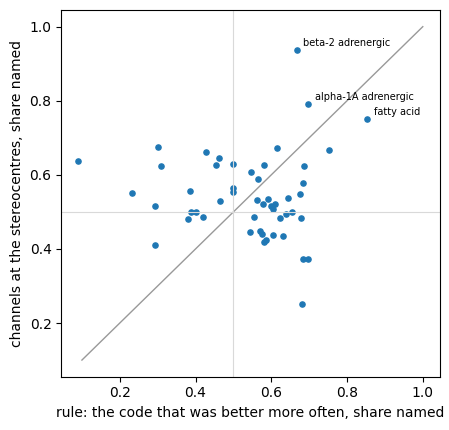

In [8]:
ref = en.configuration_reference(sets, stored["difference"])
print("%-27s %-12s %6s %9s %9s %9s   %-26s %-26s" % ("pairs", "differing by", "n", "channels", "rule low", "rule high",
                                                    "channels minus rule low", "channels minus rule high"))
for subset, cells in ref["pooled"].items():
    for margin, c in cells.items():
        low, high = c["model minus lowest"], c["model minus highest"]
        print("%-27s %-12s %6d %8.1f%% %8.1f%% %8.1f%%   %+.1f [%+.1f, %+.1f]%s %+.1f [%+.1f, %+.1f]" % (
            subset, margin.split()[1] + " or more", c["pairs"], 100 * c["model"], 100 * c["lowest"], 100 * c["highest"],
            100 * low["mean"], 100 * low["low"], 100 * low["high"], " " * 6,
            100 * high["mean"], 100 * high["low"], 100 * high["high"]))
all_pairs = ref["pooled"]["all pairs"]["margin 1.0"]
print()
print("agreement of the channels and the rule on the 1,144 pairs: %.1f %%" % (100 * all_pairs["agreement of the model and the rule (lowest)"]))
print("targets above 50 %%: channels %d, rule low %d, rule high %d of %d" % (
    ref["above one half"]["model"], ref["above one half"]["lowest"], ref["above one half"]["highest"], len(ref["targets"])))
for t in ref["targets"]:
    if t["target"] in ("beta-2_adrenergic_receptor", "alpha-1A_adrenergic_receptor", "fatty_acid_amide_hydrolase"):
        print("  %-30s %3d pairs: channels %.1f %%, rule low %.1f %%, rule high %.1f %%" % (
            t["target"].replace("_", " "), t["pairs"], 100 * t["model"], 100 * t["lowest"], 100 * t["highest"]))

fig, ax = plt.subplots(figsize=(4.6, 4.4))
model_share = [t["model"] for t in ref["targets"]]
rule_share = [t["lowest"] for t in ref["targets"]]
ax.scatter(rule_share, model_share, s=14, color="tab:blue")
ax.plot([0.1, 1], [0.1, 1], color="0.6", lw=1)
ax.axhline(0.5, color="0.85", lw=0.8)
ax.axvline(0.5, color="0.85", lw=0.8)
for t in ref["targets"]:
    if t["target"] in ("beta-2_adrenergic_receptor", "alpha-1A_adrenergic_receptor", "fatty_acid_amide_hydrolase"):
        ax.annotate(t["target"].replace("_", " ").replace(" receptor", "").replace(" amide hydrolase", ""),
                    (t["lowest"], t["model"]), textcoords="offset points", xytext=(5, 3), fontsize=7)
ax.set_xlabel("rule: the code that was better more often, share named")
ax.set_ylabel("channels at the stereocentres, share named")
plt.tight_layout()
plt.show()

The channels and the rule do equally well when all pairs are counted. At the centre of lowest
rank, the channels are 0.8 points below the rule with all pairs (an interval from -2.8 to +1.2
points) and 0.9 points above it with the pairs that differ by a log unit or more (-2.7 to +4.5).
The interval contains zero in every row of that column. With the centre of highest rank the rule is
worse on the pairs with several centres, and over all pairs that differ by a log unit or more the
channels are 4.4 points ahead (an interval from +1.1 to +7.6). So the answer depends on a choice of
centre that nobody can justify, and the comparison is cleanest on the pairs with one centre. There
the channels are 2.7 points ahead of the first rule and 3.8 points ahead of the second, and both
intervals contain zero.

Two more facts. The two do not read the same thing: they agree on the better member in only 52 %
of the pairs, which is what two independent guesses of this accuracy would give. And they differ
by target. The channels are far ahead of the rule on the beta-2 receptor (93.6 % against 66.7 %)
and ahead on the alpha-1A receptor (79.1 % against 69.8 %), and the rule is ahead on fatty acid
amide hydrolase (85.2 % against 75.0 %). Whether the two together are better than each alone was not tried.

So the channels name the better enantiomer about as often as a bit that says which hand a target
prefers. The claim of the manual stands as it was written: the signal is real, small, and at the
stereocentre. It is not shown to be more than a configuration label. On a few targets, such as the
beta-2 receptor, the channels are far ahead of the rule, but the series is too small to test each
of them alone.

## What to take from this notebook

- The null of a blind description can be exact. Here the two members of a pair have identical
  two-point rows, so a model without handedness channels must score 50.0 %. Check that score
  first. It found 260 split pairs in the folds.
- Hold out whole groups, and take the configuration off a molecule before reading its scaffold.
  A split pair is ranked backwards on purpose.
- The handedness channels carry a small real signal about which enantiomer is better. It survives
  holding out scaffolds, it sits at the stereocentre, and it does not improve the prediction of
  the potency itself.
- Put the cheap rule in the references. One bit for each target, the configuration code, does as
  well as the channels on all pairs, and the channels beat it clearly only on a few targets. A
  rule that has a free choice, here the centre, has to be given with both ends of the choice.
- A difference between two enantiomers is often small: half of the pairs differ by half a log
  unit or less, and a reported difference can be below the error of its assay.

From the command line:

```
python benchmarks/run_enantiomers.py --reference      # only the rule, from the saved result (about 35 seconds)
python benchmarks/run_enantiomers.py                  # the whole measurement (about 17 minutes)
```

Where to read further in the manual: *Two enantiomers of the same compound, both measured* has the
series, the exact null, the two fold rules and the localisation at the stereocentre, and
*Three tests to run before you build a new field or a new score* gives the kind of question that
this notebook asks of the channels.